In [1]:
import numpy as np

x = np.array([0, 1, 2, 3])
y = np.array([0, 1, 0, 1])

h = np.diff(x)
print(h)


[1 1 1]


NACA airfoil: NACA 3410
Maximum camber  c = 0.03
Location of maximum camber x = 0.4
Maximum thickness ratio t = 0.1


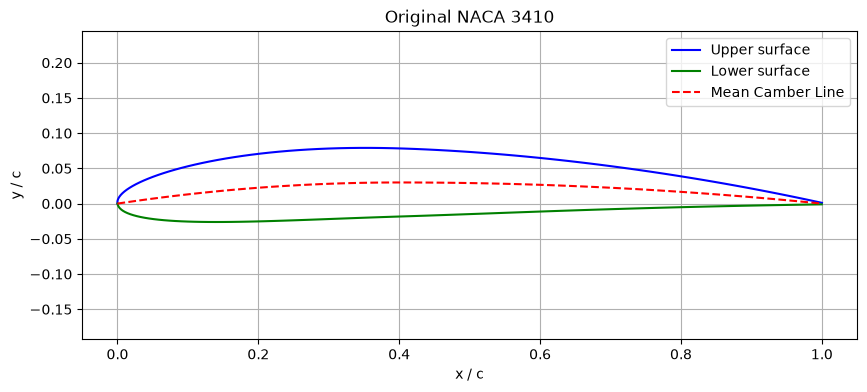

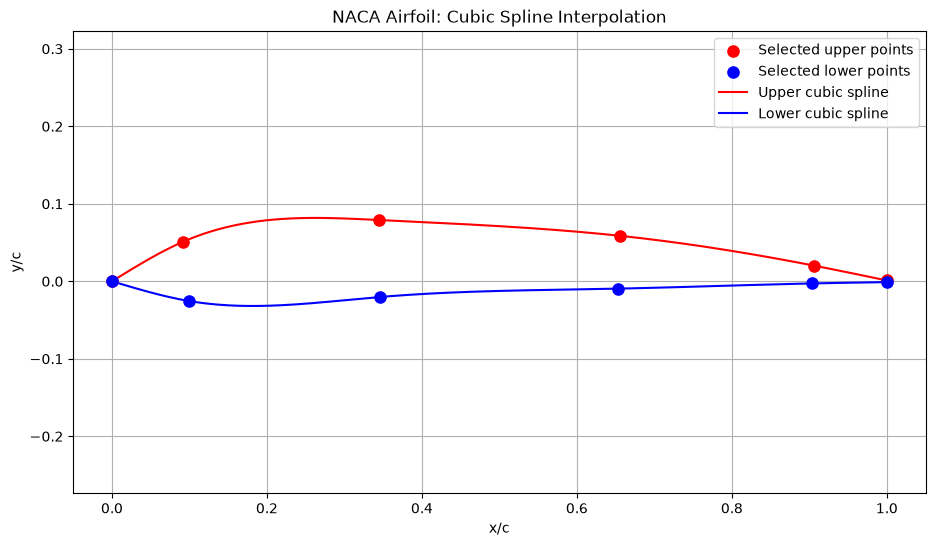

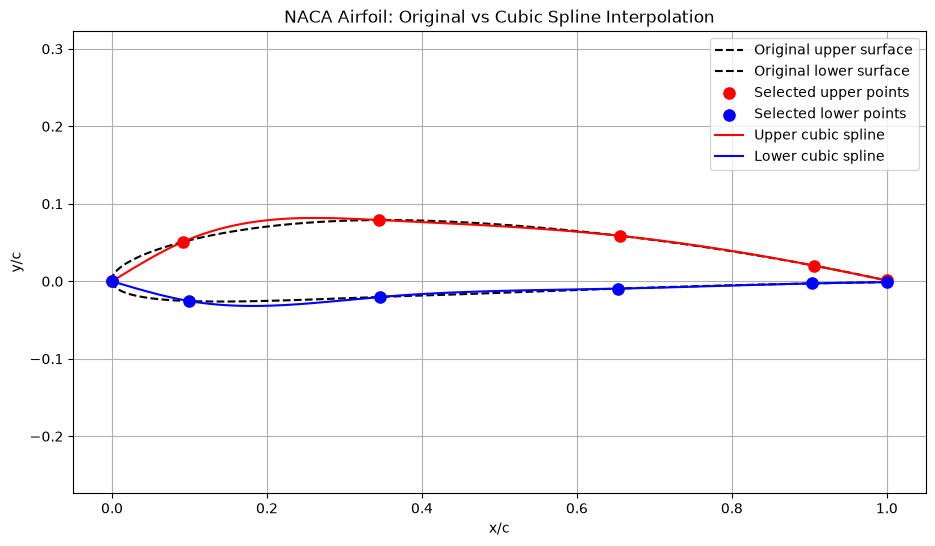

[0.         0.09113783 0.34447692 0.65595356 0.90548005 1.00010448]
[0.         0.05074032 0.07907813 0.05866932 0.02034376 0.00104479]
[0.         0.09984518 0.34650608 0.65306343 0.90353694 0.99989552]
[ 0.         -0.02551236 -0.02019232 -0.00946509 -0.00276523 -0.00104479]
NACA Airfoil: 3410

UPPER SURFACE
Maximum absolute error: 0.0117961985533543
RMS error: 0.00392393234495916

LOWER SURFACE
Maximum absolute error: 0.0097750605199105
RMS error: 0.00324551620354393

COMBINED AIRFOIL
Maximum absolute error: 0.0117961985533543
RMS error: 0.00360073745747194


In [7]:
# random number generator for NACA 4-digit airfoil
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng()

m = rng.choice([0.00, 0.01, 0.02, 0.03, 0.04])
p = rng.choice([0.2, 0.3, 0.4, 0.5])
t = rng.choice([0.08, 0.10, 0.12, 0.15])

M = int(round(m * 100))
P = int(round(p * 10))
T = int(round(t * 100))


print("NACA airfoil: NACA {}{}{:02d}".format(M, P, T))
print("Maximum camber  c =", m)
print("Location of maximum camber x =", p)
print("Maximum thickness ratio t =", t)


       #########################################################################

# Original NACA airfoil plotting

# Chordwise locations
N = 101
beta = np.linspace(0, np.pi, N)
x = (1 - np.cos(beta)) / 2

# Thickness distribution
yt = 5 * t * (
    0.2969 * np.sqrt(x)
    - 0.1260 * x
    - 0.3516 * x**2
    + 0.2843 * x**3
    - 0.1015 * x**4)


# Mean camber line and its slope
yc = np.zeros(N)
dyc = np.zeros(N)

for i in range(N):
    if x[i] <= p:
        yc[i] = (m / p**2) * (2*p*x[i] - x[i]**2)
        dyc[i] = (2*m / p**2) * (p - x[i])
    else:
        yc[i] = (m / (1-p)**2) * (
            (1 - 2*p) + 2*p*x[i] - x[i]**2)
        dyc[i] = (2*m / (1-p)**2) * (p - x[i])

theta = np.arctan(dyc)

xu = x - yt * np.sin(theta)
yu = yc + yt * np.cos(theta)

xl = x + yt * np.sin(theta)
yl = yc - yt * np.cos(theta)


plt.figure(figsize=(10, 4))

plt.plot(xu, yu, label="Upper surface", color="blue")
plt.plot(xl, yl, label="Lower surface", color="green")
plt.plot(x, yc, "--", label="Mean Camber Line", color="red")

plt.xlabel("x / c")
plt.ylabel("y / c")
plt.title("Original NACA {}{}{:02d}".format(M, P, T))
plt.axis("equal")
plt.grid(True)
plt.legend()
plt.show()


      #########################################################################

# Select six points from each surface
N_points = 6
indices = np.linspace(0, N-1, N_points, dtype=int)

x_upper = xu[indices]
y_upper = yu[indices]

x_lower = xl[indices]
y_lower = yl[indices]

# Sorting because x range must be in increasing order
order_upper = np.argsort(x_upper)
x_upper = x_upper[order_upper]
y_upper = y_upper[order_upper]

order_lower = np.argsort(x_lower)
x_lower = x_lower[order_lower]
y_lower = y_lower[order_lower]



#########################################################################################

# Cubic Spline Interpolation

def spline_2nd_derivatives(x, y):
    
    n = len(x)

    if n < 3:
        raise ValueError("At least three data points are required.")

    if np.any(np.diff(x) <= 0):
        raise ValueError("The x values must be strictly increasing.")

    h = np.diff(x)

    A = np.zeros((n - 2, n - 2))
    b = np.zeros(n - 2) 

    for i in range(1, n - 1):
         row = i - 1

         b[row] = 6 * ((y[i + 1] - y[i]) / h[i]- (y[i] - y[i - 1]) / h[i - 1])
         A[row, row] = 2 * (h[i - 1] + h[i])
         if i > 1:
             A[row, row - 1] = h[i - 1]
         if i < n - 2:
             A[row, row + 1] = h[i]

    M_inner = np.linalg.solve(A, b)
    M = np.zeros(n)
    M[1:-1] = M_inner

    return h, M
   


h_upper, M_upper = spline_2nd_derivatives(x_upper, y_upper)
h_lower, M_lower = spline_2nd_derivatives(x_lower, y_lower)



def cubic_spline_value(x, y, h, M, xq):

    if xq < x[0] or xq > x[-1]:
        raise ValueError("Query point is outside the data range")

    i = np.searchsorted(x, xq) - 1 
    i = max(0, min(i, len(x) - 2)) # Restrict to a valid interval

    S = (M[i] * (x[i + 1] - xq)**3 / (6 * h[i])
        + M[i + 1] * (xq - x[i])**3 / (6 * h[i])
        + (y[i] - M[i] * h[i]**2 / 6)
        * (x[i + 1] - xq) / h[i]
        + (y[i + 1] - M[i + 1] * h[i]**2 / 6)
        * (xq - x[i]) / h[i])

    return S


x_plot_upper = np.linspace(x_upper[0], x_upper[-1], 300)
x_plot_lower = np.linspace(x_lower[0], x_lower[-1], 300)

y_plot_upper = np.array([
    cubic_spline_value(x_upper, y_upper, h_upper, M_upper, xq)for xq in x_plot_upper])

y_plot_lower = np.array([
    cubic_spline_value(x_lower, y_lower, h_lower, M_lower, xq)for xq in x_plot_lower])


        ########################################################################

# Plotting the reconstructed airfoil
plt.figure(figsize=(11, 6))

plt.scatter(x_upper, y_upper, color="red", s=65,label="Selected upper points", zorder=3)
plt.scatter(x_lower, y_lower, color="blue", s=65,label="Selected lower points", zorder=3)

plt.plot(x_plot_upper, y_plot_upper, "r-",label="Upper cubic spline")
plt.plot(x_plot_lower, y_plot_lower, "b-",label="Lower cubic spline")

plt.xlabel("x/c")
plt.ylabel("y/c")
plt.title("NACA Airfoil: Cubic Spline Interpolation")
plt.axis("equal")
plt.axis("equal")
plt.grid(True)
plt.legend()
plt.show()


        ########################################################################


# Plotting the original and reconstructed airfoil
plt.figure(figsize=(11, 6))

plt.plot(xu, yu, "k--", label="Original upper surface")
plt.plot(xl, yl, "k--", label="Original lower surface")

plt.scatter(x_upper, y_upper, color="red", s=65,label="Selected upper points", zorder=3)
plt.scatter(x_lower, y_lower, color="blue", s=65,label="Selected lower points", zorder=3)

plt.plot(x_plot_upper, y_plot_upper, "r-",label="Upper cubic spline")
plt.plot(x_plot_lower, y_plot_lower, "b-",label="Lower cubic spline")

plt.xlabel("x/c")
plt.ylabel("y/c")
plt.title("NACA Airfoil: Original vs Cubic Spline Interpolation")
plt.axis("equal")
plt.axis("equal")
plt.grid(True)
plt.legend()
plt.show()


       ########################################################################

print(x_upper)
print(y_upper)
print(x_lower)
print(y_lower)

# Error calculation
x_eval_upper = np.linspace(x_upper[0], x_upper[-1], 300)
x_eval_lower = np.linspace(x_lower[0], x_lower[-1], 300)

y_reference_upper = np.interp(x_eval_upper,np.sort(xu),yu[np.argsort(xu)])
y_reference_lower = np.interp(x_eval_lower,np.sort(xl),yl[np.argsort(xl)])

y_spline_upper = np.array([
    cubic_spline_value(x_upper, y_upper, h_upper, M_upper, xq)for xq in x_eval_upper])

y_spline_lower = np.array([
    cubic_spline_value(x_lower, y_lower, h_lower, M_lower, xq)for xq in x_eval_lower])

error_upper = y_reference_upper - y_spline_upper
error_lower = y_reference_lower - y_spline_lower

max_error_upper = np.max(np.abs(error_upper))
max_error_lower = np.max(np.abs(error_lower))

rms_upper = np.sqrt(np.mean(error_upper**2))
rms_lower = np.sqrt(np.mean(error_lower**2))

all_errors = np.concatenate((error_upper, error_lower))

max_error_combined = np.max(np.abs(all_errors))
rms_combined = np.sqrt(np.mean(all_errors**2))

print("NACA Airfoil: {}{}{:02d}".format(M, P, T))

print("\nUPPER SURFACE")
print(f"Maximum absolute error: {max_error_upper:.16f}")
print(f"RMS error: {rms_upper:.17f}")

print("\nLOWER SURFACE")
print(f"Maximum absolute error: {max_error_lower:.16f}")
print(f"RMS error: {rms_lower:.17f}")

print("\nCOMBINED AIRFOIL")
print(f"Maximum absolute error: {max_error_combined:.16f}")
print(f"RMS error: {rms_combined:.17f}")
